<a href="https://colab.research.google.com/github/dudekulapeeravali2537sse-bot/ITA0616/blob/main/EXP_14.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

HOUSE PRICE DATASET
   Area  Bedrooms  Bathrooms  Age  Price
0  1000         2          1   10     25
1  1200         2          2    8     30
2  1500         3          2    5     40
3  1800         3          2    4     48
4  2000         3          3    3     55

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Area       30 non-null     int64
 1   Bedrooms   30 non-null     int64
 2   Bathrooms  30 non-null     int64
 3   Age        30 non-null     int64
 4   Price      30 non-null     int64
dtypes: int64(5)
memory usage: 1.3 KB
None

Dataset Shape: (30, 5)

Missing Values:
Area         0
Bedrooms     0
Bathrooms    0
Age          0
Price        0
dtype: int64

Model Training Completed Successfully!

ACTUAL VS PREDICTED HOUSE PRICES
   Actual Price  Predicted Price
0            49            49.84
1            65            64.99

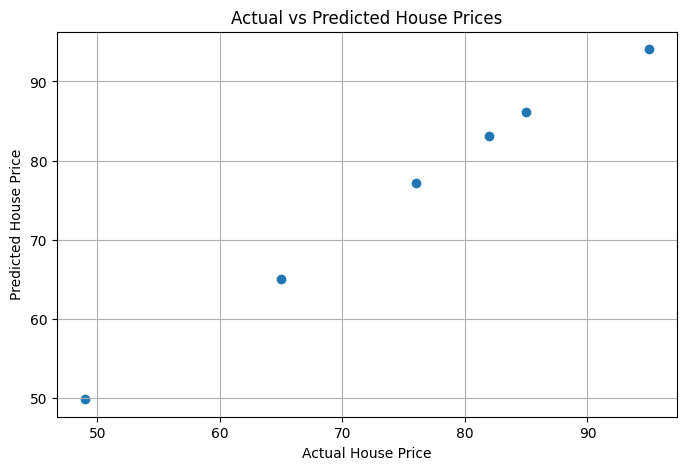


MODEL COEFFICIENTS
Area : 0.0305
Bedrooms : 1.6375
Bathrooms : 0.2188
Age : 0.2182
Intercept: -13.0225

NEW HOUSE DETAILS
   Area  Bedrooms  Bathrooms  Age
0  2000         3          2    5

Predicted House Price: 54.42 Lakhs


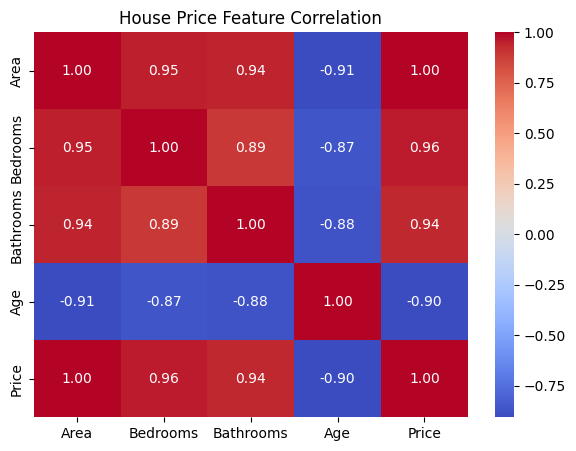

In [1]:

# HOUSE PRICE PREDICTION USING MACHINE LEARNING
# Algorithm: Multiple Linear Regression

# Step 1: Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

# Step 2: Create House Dataset
data = {
    'Area': [
        1000, 1200, 1500, 1800, 2000,
        2200, 2500, 2800, 3000, 3200,
        1100, 1300, 1600, 1900, 2100,
        2300, 2600, 2900, 3100, 3500,
        1400, 1700, 2400, 2700, 3300,
        1250, 1550, 1850, 2250, 2750
    ],

    'Bedrooms': [
        2, 2, 3, 3, 3,
        4, 4, 4, 4, 5,
        2, 2, 3, 3, 3,
        4, 4, 4, 5, 5,
        3, 3, 4, 4, 5,
        2, 3, 3, 4, 4
    ],

    'Bathrooms': [
        1, 2, 2, 2, 3,
        3, 3, 3, 4, 4,
        1, 2, 2, 2, 3,
        3, 3, 4, 4, 4,
        2, 2, 3, 3, 4,
        2, 2, 2, 3, 3
    ],

    'Age': [
        10, 8, 5, 4, 3,
        5, 3, 2, 1, 2,
        12, 9, 6, 5, 4,
        3, 2, 1, 2, 1,
        7, 6, 4, 3, 2,
        10, 7, 5, 4, 2
    ],

    'Price': [
        25, 30, 40, 48, 55,
        62, 70, 78, 85, 95,
        27, 32, 42, 50, 58,
        65, 73, 82, 90, 105,
        37, 45, 68, 76, 98,
        29, 41, 49, 64, 80
    ]
}

df = pd.DataFrame(data)

# Step 3: Display Dataset
print("HOUSE PRICE DATASET")
print(df.head())

print("\nDataset Information:")
print(df.info())

print("\nDataset Shape:", df.shape)

# Step 4: Check Missing Values
print("\nMissing Values:")
print(df.isnull().sum())

# Step 5: Separate Input and Output
X = df[['Area', 'Bedrooms', 'Bathrooms', 'Age']]
y = df['Price']

# Step 6: Split Dataset into Training and Testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Step 7: Create Linear Regression Model
model = LinearRegression()

# Step 8: Train the Model
model.fit(X_train, y_train)

print("\nModel Training Completed Successfully!")

# Step 9: Predict House Prices
y_pred = model.predict(X_test)

print("\nACTUAL VS PREDICTED HOUSE PRICES")

results = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': np.round(y_pred, 2)
})

print(results)

# Step 10: Evaluate Model Performance
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nMODEL PERFORMANCE")
print("Mean Absolute Error:", round(mae, 2))
print("Mean Squared Error:", round(mse, 2))
print("Root Mean Squared Error:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

# Step 11: Visualize Actual vs Predicted Prices
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, marker='o')
plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted House Prices")
plt.grid(True)
plt.show()

# Step 12: Display Feature Importance (Coefficients)
print("\nMODEL COEFFICIENTS")

for feature, coefficient in zip(X.columns, model.coef_):
    print(feature, ":", round(coefficient, 4))

print("Intercept:", round(model.intercept_, 4))

# Step 13: Predict Price of a New House
# Area = 2000 square feet
# Bedrooms = 3
# Bathrooms = 2
# Age = 5 years

new_house = pd.DataFrame({
    'Area': [2000],
    'Bedrooms': [3],
    'Bathrooms': [2],
    'Age': [5]
})

predicted_price = model.predict(new_house)

print("\nNEW HOUSE DETAILS")
print(new_house)

print("\nPredicted House Price:",
      round(predicted_price[0], 2), "Lakhs")

# Step 14: Plot Feature Correlation
plt.figure(figsize=(7, 5))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("House Price Feature Correlation")
plt.show()

